## ML for sports


In [44]:
import pandas as pd
from scipy.stats import ks_2samp

# ---------- 1. load ----------
df = pd.read_csv("regular_season_totals_2010_2024.csv")

# ---------- 2. team-only derived stats (before the merge) ----------
df["EFG_PCT"] = (df.FGM + 0.5*df.FG3M) / df.FGA
df["TS_PCT"]  = df.PTS / (2*(df.FGA + 0.44*df.FTA))
df["FG3AR"]   = df.FG3A / df.FGA
df["FTR"]     = df.FTA / df.FGA
df["AST_PCT"] = df.AST / df.FGM
df["POSS"]    = df.FGA - df.OREB + df.TOV + 0.44*df.FTA
df["TOV_PCT"] = 100*df.TOV / (df.FGA + 0.44*df.FTA + df.TOV)
df["ORTG"]    = 100*df.PTS / df.POSS

# ---------- 3. pair each team with its opponent ----------
paired = df.merge(df, on="GAME_ID", suffixes=("_own", "_opp"))
paired = paired[paired.TEAM_ABBREVIATION_own != paired.TEAM_ABBREVIATION_opp].copy()

# ---------- 4. stats that need the opponent ----------
for a, b in [("own","opp"), ("opp","own")]:
    paired[f"ORB_PCT_{a}"] = paired[f"OREB_{a}"] / (paired[f"OREB_{a}"] + paired[f"DREB_{b}"])
    paired[f"DRB_PCT_{a}"] = paired[f"DREB_{a}"] / (paired[f"DREB_{a}"] + paired[f"OREB_{b}"])
    paired[f"TRB_PCT_{a}"] = (paired[f"OREB_{a}"] + paired[f"DREB_{a}"]) / (
        paired.OREB_own + paired.DREB_own + paired.OREB_opp + paired.DREB_opp)
    paired[f"STL_PCT_{a}"] = 100*paired[f"STL_{a}"] / paired[f"POSS_{b}"]
    paired[f"BLK_PCT_{a}"] = 100*paired[f"BLK_{a}"] / (paired[f"FGA_{b}"] - paired[f"FG3A_{b}"])
    paired[f"DRTG_{a}"]    = 100*paired[f"PTS_{b}"] / paired[f"POSS_{a}"]

# ---------- 5. the paper's 25 box-score features ----------
diff_stats = ["FGM","FG_PCT","FG3M","FTM","FT_PCT","OREB","DREB","AST","STL","BLK","TOV","PF",
              "TS_PCT","EFG_PCT","FG3AR","FTR","ORB_PCT","DRB_PCT","TRB_PCT","AST_PCT",
              "STL_PCT","BLK_PCT","TOV_PCT","ORTG","DRTG"]
for s in diff_stats:
    paired[f"{s}_DIFF"] = paired[f"{s}_own"] - paired[f"{s}_opp"]

# ---------- 6. season-to-date averages, excluding the current game ----------
paired = paired.sort_values(["TEAM_ABBREVIATION_own","SEASON_YEAR_own","GAME_DATE_own"])
grp = paired.groupby(["TEAM_ABBREVIATION_own","SEASON_YEAR_own"])
for s in diff_stats:
    paired[f"{s}_SEASON_AVG"] = grp[f"{s}_DIFF"].transform(lambda x: x.shift(1).expanding().mean())
paired["GAME_NUM"] = grp.cumcount() + 1

# ---------- 7. previous season win% ----------
season_wl = (df.groupby(["TEAM_ABBREVIATION","SEASON_YEAR"])["WL"]
               .apply(lambda x: (x == "W").mean()).reset_index().rename(columns={"WL":"WIN_PCT"}))
season_wl = season_wl.sort_values(["TEAM_ABBREVIATION","SEASON_YEAR"])
season_wl["PREV_SEASON_WIN_PCT"] = season_wl.groupby("TEAM_ABBREVIATION")["WIN_PCT"].shift(1)
paired = paired.merge(season_wl[["TEAM_ABBREVIATION","SEASON_YEAR","PREV_SEASON_WIN_PCT"]],
                      left_on=["TEAM_ABBREVIATION_own","SEASON_YEAR_own"],
                      right_on=["TEAM_ABBREVIATION","SEASON_YEAR"], how="left")

# ---------- 8. one row per game: home minus away ----------
paired["IS_HOME"] = paired.MATCHUP_own.str.contains("vs.")
keep = [f"{s}_SEASON_AVG" for s in diff_stats] + ["PREV_SEASON_WIN_PCT","GAME_NUM"]
home = paired[paired.IS_HOME][["GAME_ID","SEASON_YEAR_own","GAME_DATE_own",
                               "TEAM_ABBREVIATION_own","WL_own"] + keep]
away = paired[~paired.IS_HOME][["GAME_ID"] + keep]
games = home.merge(away, on="GAME_ID", suffixes=("_h","_a"))

for s in diff_stats:
    games[s] = games[f"{s}_SEASON_AVG_h"] - games[f"{s}_SEASON_AVG_a"]
games["PREV_SEASON_WP"] = games.PREV_SEASON_WIN_PCT_h - games.PREV_SEASON_WIN_PCT_a
games["TARGET"] = (games.WL_own == "W").astype(int)          # 1 = home team won

# ---------- 9. drop each team's first 10 games of the season ----------
games = games[(games.GAME_NUM_h > 10) & (games.GAME_NUM_a > 10)].copy()

# ---------- 10. splits (the paper's seasons) ----------
train_seasons      = ["2014-15","2015-16"]
val_season         = "2016-17"
test_season        = "2017-18"
betting_sim_season = "2018-19"

feature_cols = diff_stats + ["PREV_SEASON_WP"]
train_df   = games[games.SEASON_YEAR_own.isin(train_seasons)].copy()
val_df     = games[games.SEASON_YEAR_own == val_season].copy()
test_df    = games[games.SEASON_YEAR_own == test_season].copy()
betting_df = games[games.SEASON_YEAR_own == betting_sim_season].copy()

# ---------- 11. covariate shift: validation vs training, 1% level ----------
features_to_drop = [c for c in feature_cols
                    if ks_2samp(train_df[c].dropna(), val_df[c].dropna())[1] < 0.01]
feature_cols_final = [c for c in feature_cols if c not in features_to_drop]

print("games:", len(games))
print("train/val/test/betting:", len(train_df), len(val_df), len(test_df), len(betting_df))
print("home win rate (train):", round(train_df.TARGET.mean(), 3))
print("dropped for shift:", features_to_drop)
print("features kept:", len(feature_cols_final))

games: 14471
train/val/test/betting: 2145 1074 1075 1074
home win rate (train): 0.585
dropped for shift: ['OREB']
features kept: 25


In [45]:
# ---------- 12. standardisation (train and val only) ----------
ref = games[games.SEASON_YEAR_own.isin(train_seasons)]
mu, sd = ref[feature_cols_final].mean(), ref[feature_cols_final].std()
for split in (train_df, val_df):
    split[feature_cols_final] = (split[feature_cols_final] - mu) / sd

In [46]:
# ---------- 13. odds merge (into g2, leaving games intact) ----------
import sqlite3

g2 = games.rename(columns={"TEAM_ABBREVIATION_own": "HOME_ABBR"}).copy()
aw = (paired.loc[~paired.IS_HOME, ["GAME_ID","TEAM_ABBREVIATION_own"]]
            .rename(columns={"TEAM_ABBREVIATION_own":"AWAY_ABBR"}))
g2 = g2.merge(aw, on="GAME_ID", how="left")
g2["GAME_DATE"] = pd.to_datetime(g2.GAME_DATE_own).dt.normalize()

name_to_abbr = dict(zip(df.TEAM_NAME, df.TEAM_ABBREVIATION))
conn = sqlite3.connect("OddsData.sqlite")
all_seasons = train_seasons + [val_season, test_season, betting_sim_season]
odds = pd.concat([pd.read_sql_query(f'SELECT * FROM "odds_{s}"', conn).assign(SEASON_YEAR_own=s)
                  for s in all_seasons], ignore_index=True)
odds["HOME_ABBR"] = odds.Home.map(name_to_abbr)
odds["AWAY_ABBR"] = odds.Away.map(name_to_abbr)

def pdate(r):                       # "2014-15-1028" -> 2014-10-28
    y0 = int(r.SEASON_YEAR_own[:4]); m = int(r.Date[-4:-2]); d = int(r.Date[-2:])
    return pd.Timestamp(year=y0 if m >= 10 else y0+1, month=m, day=d)
odds["GAME_DATE"] = odds.apply(pdate, axis=1)

odds = odds[["GAME_DATE","HOME_ABBR","AWAY_ABBR","ML_Home","ML_Away"]].drop_duplicates(
        subset=["GAME_DATE","HOME_ABBR","AWAY_ABBR"])
g2 = g2.merge(odds, on=["GAME_DATE","HOME_ABBR","AWAY_ABBR"], how="left")

print(len(g2), "rows, missing odds:", g2.ML_Home.isna().sum())

14471 rows, missing odds: 9103


In [47]:
# ---------- 14. subset A: Spearman correlation filter ----------
X = train_df[feature_cols_final]
y = train_df["TARGET"]
corr = X.corr(method="spearman").abs()
tgt  = X.corrwith(y, method="spearman").abs()

dropped = set()
pairs = [(a,b) for i,a in enumerate(feature_cols_final) for b in feature_cols_final[i+1:]]
for a, b in sorted(pairs, key=lambda ab: -corr.loc[ab]):      # tightest pairs first
    if a in dropped or b in dropped:
        continue
    if corr.loc[a, b] > 0.7:
        dropped.add(b if tgt[a] >= tgt[b] else a)             # keep the one closer to the target

subset_A = [c for c in feature_cols_final if c not in dropped]

In [48]:
import numpy as np

def classwise_ece(y_true, y_prob, n_bins=20, min_nonempty=0.8):
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    edges = np.linspace(0, 1, n_bins+1)
    idx = np.clip(np.digitize(y_prob, edges[1:-1]), 0, n_bins-1)
    n = len(y_prob); ece = 0.0; nonempty = 0
    for j in range(n_bins):
        m = idx == j
        if not m.any():
            continue
        nonempty += 1
        ece += (m.sum()/n) * abs(y_true[m].mean() - y_prob[m].mean())
    if nonempty / n_bins < min_nonempty:     # paper's anti-cheat constraint
        return 1.0
    return ece

In [49]:
import numpy as np
from sklearn.linear_model import LogisticRegression
ytr = train_df.TARGET.values
yva = val_df.TARGET.values

def score(cols, metric):
    m = LogisticRegression(max_iter=1000).fit(train_df[cols], ytr)
    p = m.predict_proba(val_df[cols])[:, 1]
    return classwise_ece(yva, p) if metric == "ece" else (p.round() == yva).mean()

def sfs(metric):
    chosen, rest, path = [], list(subset_A), []
    while rest:                                    # completion of search
        cand = [(score(chosen + [f], metric), f) for f in rest]
        best = min(cand) if metric == "ece" else max(cand)
        chosen = chosen + [best[1]]; rest.remove(best[1])
        path.append((best[0], list(chosen)))
    return (min(path, key=lambda t: t[0]) if metric == "ece"
            else max(path, key=lambda t: t[0]))

ece_b, subset_B = sfs("ece")     # calibration branch
acc_c, subset_C = sfs("acc")     # accuracy branch

In [50]:
print("A:", len(subset_A), subset_A)
print("B:", subset_B, "ECE %.4f" % ece_b)
print("C:", subset_C, "acc %.4f" % acc_c)

A: 9 ['FG3M', 'FT_PCT', 'DREB', 'AST', 'BLK', 'TOV', 'PF', 'ORTG', 'PREV_SEASON_WP']
B: ['ORTG', 'FG3M'] ECE 0.0379
C: ['ORTG', 'PREV_SEASON_WP', 'FG3M', 'TOV'] acc 0.6518


In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

def make_models(seed=0):
    return {
        "LR":  LogisticRegression(max_iter=1000, random_state=seed),
        "RF":  RandomForestClassifier(random_state=seed),
        "SVM": SVC(probability=True, random_state=seed),
        "MLP": MLPClassifier(max_iter=2000, random_state=seed),
    }

# extended training set and test set, both on the train+val scale
r2 = games[games.SEASON_YEAR_own.isin(train_seasons + [val_season])]
m2, s2 = r2[feature_cols_final].mean(), r2[feature_cols_final].std()

ext = games[games.SEASON_YEAR_own.isin(train_seasons + [val_season])].copy()
ext[feature_cols_final] = (ext[feature_cols_final] - m2) / s2

test_df = games[games.SEASON_YEAR_own == test_season].copy()      # from raw, not the scaled copy
test_df[feature_cols_final] = (test_df[feature_cols_final] - m2) / s2

print("ext  mean %+.4f sd %.4f" % (ext[feature_cols_final].mean().mean(),
                                    ext[feature_cols_final].std().mean()))
print("test mean %+.4f sd %.4f" % (test_df[feature_cols_final].mean().mean(),
                                    test_df[feature_cols_final].std().mean()))

ext  mean -0.0000 sd 1.0000
test mean +0.0068 sd 0.9543


In [52]:
import numpy as np, optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

HIDDEN = [(a,) for a in (3,4,5,6)] + [(a,b) for a in (3,4,5,6) for b in (3,4,5,6)]

In [53]:
def _suggest_svm_mlp(trial, name, seed):
    if name == "SVM":
        return SVC(
            C=trial.suggest_float("C", 0.1, 50),
            kernel=trial.suggest_categorical("kernel", ["linear","rbf","sigmoid"]),
            degree=trial.suggest_int("degree", 2, 4),
            probability=True, max_iter=200000, cache_size=500, random_state=seed)
    return MLPClassifier(
        hidden_layer_sizes=HIDDEN[trial.suggest_int("hidden_idx", 0, len(HIDDEN)-1)],
        solver=trial.suggest_categorical("solver", ["lbfgs","sgd","adam"]),
        activation=trial.suggest_categorical("activation", ["identity","logistic","tanh","relu"]),
        learning_rate=trial.suggest_categorical("learning_rate", ["constant","invscaling","adaptive"]),
        learning_rate_init=trial.suggest_float("lr_init", 1e-3, 1e-1, log=True),
        alpha=trial.suggest_float("alpha", 1e-4, 1e-1, log=True),
        batch_size=trial.suggest_categorical("batch_size", [32,64,128]),
        max_iter=2000, random_state=seed)

In [54]:
def suggest(trial, name, n_feat, seed):
    if name == "LR":
        return LogisticRegression(
            C=float(np.exp(trial.suggest_float("lnC", -3, 3))),
            solver=trial.suggest_categorical("solver", ["liblinear","lbfgs"]),
            max_iter=1000, random_state=seed)
    if name == "RF":
        return RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 10, 100),
            max_depth=trial.suggest_int("max_depth", 5, 50),
            criterion=trial.suggest_categorical("criterion", ["gini","entropy"]),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 11),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 11),
            max_features=trial.suggest_int("max_features", 1, n_feat),
            random_state=seed)
    return _suggest_svm_mlp(trial, name, seed)

In [55]:
def optimise(name, cols, Xtr, ytr, Xva, yva, metric, ece_fn, n_trials=30, seed=0):
    def objective(trial):
        m = suggest(trial, name, len(cols), seed)
        try:
            m.fit(Xtr[cols], ytr)
            p = m.predict_proba(Xva[cols])[:,1]
        except Exception:
            return 1.0 if metric == "ece" else 0.0
        return ece_fn(yva, p) if metric == "ece" else -(p.round() == yva).mean()
    st = optuna.create_study(direction="minimize",
                             sampler=optuna.samplers.TPESampler(seed=seed))
    st.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    return st.best_params, st.best_value

In [56]:
import time, json
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
best_params = {}
results = {}

for metric, cols, tag in [("ece", subset_B, "B"), ("acc", subset_C, "C")]:
    for name in ["LR", "RF", "MLP", "SVM"]:
        t = time.time()
        bp, bv = optimise(name, cols, train_df, ytr, val_df, yva,
                          metric, classwise_ece, n_trials=30)
        score = bv if metric == "ece" else -bv          # optuna minimises, so flip accuracy back
        best_params[f"{tag}_{name}"] = bp
        results[f"{tag}_{name}"] = score
        print(f"{tag} {name:4} {'ECE' if metric=='ece' else 'acc'}={score:.4f}  {time.time()-t:5.1f}s",
              flush=True)

json.dump(best_params, open("best_params.json", "w"), indent=1)

B LR   ECE=0.0351    0.2s
B RF   ECE=0.0449    6.0s
B MLP  ECE=0.0348   10.0s
B SVM  ECE=0.0378   23.7s
C LR   acc=0.6536    0.2s
C RF   acc=0.6443    9.6s
C MLP  acc=0.6574   17.2s
C SVM  acc=0.6574   43.3s


In [57]:
def fixed(name, params, n_feat, seed):
    """Rebuild a model from stored params by replaying them through suggest()."""
    class T:
        def suggest_float(s, k, *a, **kw):    return params[k]
        def suggest_int(s, k, *a, **kw):      return params[k]
        def suggest_categorical(s, k, *a):    return params[k]
    return suggest(T(), name, n_feat, seed)

In [58]:
import numpy as np, pandas as pd, warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# ext and test_df are already built and scaled in the make_models cell
yext = ext.TARGET.values
yte  = test_df.TARGET.values
SEEDS = range(10)
sel = {}

print("ext sd", round(ext[feature_cols_final].std().mean(), 4),
      "| test sd", round(test_df[feature_cols_final].std().mean(), 4))

ext sd 1.0 | test sd 0.9543


In [59]:
for metric, cols, tag in [("ece", subset_B, "B"), ("acc", subset_C, "C")]:
    for name in ["LR","RF","MLP","SVM"]:
        ps = [fixed(name, best_params[f"{tag}_{name}"], len(cols), s)
                .fit(ext[cols], yext).predict_proba(test_df[cols])[:,1] for s in SEEDS]
        p = np.mean(ps, axis=0)
        sel[f"{tag}_{name}"] = classwise_ece(yte, p) if metric=="ece" else (p.round()==yte).mean()
        print(f"{tag} {name:4} {sel[f'{tag}_{name}']:.4f}", flush=True)

best_B = min([k for k in sel if k.startswith("B_")], key=lambda k: sel[k]).split("_")[1]
best_C = max([k for k in sel if k.startswith("C_")], key=lambda k: sel[k]).split("_")[1]
print("\ncalibration-driven:", best_B, "ECE %.2f%%" % (sel["B_"+best_B]*100))
print("accuracy-driven:   ", best_C, "acc %.2f%%" % (sel["C_"+best_C]*100))

B LR   0.0431


B RF   0.0568
B MLP  0.0465
B SVM  0.0440
C LR   0.6530
C RF   0.6540
C MLP  0.6549
C SVM  0.6633

calibration-driven: LR ECE 4.31%
accuracy-driven:    SVM acc 66.33%


In [60]:
import numpy as np
 
def american_to_decimal(ml):
    ml = np.asarray(ml, dtype=float)
    return np.where(ml > 0, 1 + ml/100.0, 1 + 100.0/np.abs(ml))
 
def simulate(p_home, odds_home, odds_away, home_won, rule="fixed", margin=0.0,
             bankroll=10000.0, fixed_stake=100.0, kelly_frac=1/8):
    """As simulate(), but skip games where |p - 0.5| <= margin."""
    br=bankroll; curve=[]; n_bet=0; n_won=0
    for ph,oh,oa,won in zip(p_home,odds_home,odds_away,home_won):
        pa=1-ph; side=None
        if   ph>1/oh: side,p,o,hit = "H",ph,oh,won==1
        elif pa>1/oa: side,p,o,hit = "A",pa,oa,won==0
        if side and abs(p-0.5) > margin:          # the filter
            if rule=="kelly":
                b=o-1; stake=max(0.0, kelly_frac*((p*b-(1-p))/b)*br)
            else: stake=fixed_stake
            stake=min(stake,br); br-=stake; n_bet+=1
            if hit: br+=stake*o; n_won+=1
        curve.append(br)
    return {"final":br,"roi":100*(br-bankroll)/bankroll,
            "pct_bet":100*n_bet/len(p_home),"pct_won":100*n_won/max(n_bet,1),"curve":curve}

In [61]:
import sqlite3, numpy as np, pandas as pd

# --- rebuild g2 cleanly from games (safe to re-run) ---
g2 = games.copy()
if "TEAM_ABBREVIATION_own" in g2.columns:
    g2 = g2.rename(columns={"TEAM_ABBREVIATION_own": "HOME_ABBR"})
assert "HOME_ABBR" in g2.columns, "no home team column found in games"

stale = [c for c in g2.columns if c.startswith(("AWAY_ABBR","ML_Home","ML_Away"))]
if "GAME_DATE" in g2.columns: stale.append("GAME_DATE")
g2 = g2.drop(columns=stale, errors="ignore")

aw = (paired.loc[~paired.IS_HOME, ["GAME_ID","TEAM_ABBREVIATION_own"]]
            .rename(columns={"TEAM_ABBREVIATION_own":"AWAY_ABBR"}))
g2 = g2.merge(aw, on="GAME_ID", how="left")
g2["GAME_DATE"] = pd.to_datetime(g2.GAME_DATE_own).dt.normalize()

# --- unchanged from here down ---
n2a  = dict(zip(df.TEAM_NAME, df.TEAM_ABBREVIATION))
conn = sqlite3.connect("OddsData.sqlite")
alls = train_seasons + [val_season, test_season, betting_sim_season]
odds = pd.concat([pd.read_sql_query(f'SELECT * FROM "odds_{s}"', conn).assign(SEASON_YEAR_own=s)
                  for s in alls], ignore_index=True)
odds["HOME_ABBR"] = odds.Home.map(n2a); odds["AWAY_ABBR"] = odds.Away.map(n2a)
def pdate(r):
    y0=int(r.SEASON_YEAR_own[:4]); m=int(r.Date[-4:-2]); d=int(r.Date[-2:])
    return pd.Timestamp(year=y0 if m>=10 else y0+1, month=m, day=d)
odds["GAME_DATE"] = odds.apply(pdate, axis=1)
odds = odds[["GAME_DATE","HOME_ABBR","AWAY_ABBR","ML_Home","ML_Away"]].drop_duplicates(
        subset=["GAME_DATE","HOME_ABBR","AWAY_ABBR"])
g2 = g2.merge(odds, on=["GAME_DATE","HOME_ABBR","AWAY_ABBR"], how="left")

prior = train_seasons + [val_season, test_season]
ref   = games[games.SEASON_YEAR_own.isin(prior)]
mu, sd = ref[feature_cols_final].mean(), ref[feature_cols_final].std()

betting_df = g2[g2.SEASON_YEAR_own == betting_sim_season].sort_values("GAME_DATE").copy()
betting_df[feature_cols_final] = (betting_df[feature_cols_final] - mu) / sd
final_train = games[games.SEASON_YEAR_own.isin(prior)].copy()
final_train[feature_cols_final] = (final_train[feature_cols_final] - mu) / sd

print(len(betting_df), "games, missing odds:", betting_df.ML_Home.isna().sum())

1074 games, missing odds: 0


In [62]:
yft = final_train.TARGET.values
oh  = american_to_decimal(betting_df.ML_Home.values)
oa  = american_to_decimal(betting_df.ML_Away.values)
won = betting_df.TARGET.values

preds = {}
for tag, name, cols, key in [("Calibration", best_B, subset_B, "B_"),
                             ("Accuracy",    best_C, subset_C, "C_")]:
    ps = [fixed(name, best_params[key+name], len(cols), s)
            .fit(final_train[cols], yft).predict_proba(betting_df[cols])[:,1]
          for s in range(10)]
    preds[tag] = (name, np.mean(ps, axis=0))
    for rule in ["fixed", "kelly"]:
        r = simulate(preds[tag][1], oh, oa, won, rule)
        print(f"{tag:12} {name:4} {rule:6} final ${r['final']:9,.2f}  "
              f"ROI {r['roi']:+7.2f}%  bet {r['pct_bet']:.1f}%  won {r['pct_won']:.1f}%")

Calibration  LR   fixed  final $10,097.74  ROI   +0.98%  bet 85.3%  won 38.0%
Calibration  LR   kelly  final $ 6,500.40  ROI  -35.00%  bet 85.3%  won 38.0%
Accuracy     SVM  fixed  final $12,502.98  ROI  +25.03%  bet 88.6%  won 34.9%
Accuracy     SVM  kelly  final $ 4,488.59  ROI  -55.11%  bet 88.6%  won 34.9%


In [63]:
for tag, (name, p) in preds.items():
    print(f"{tag:12} {name:4} ECE {classwise_ece(won, p)*100:5.2f}%  "
          f"acc {(p.round()==won).mean()*100:5.2f}%  "
          f"mean p {p.mean():.3f}  sd {p.std():.3f}")

Calibration  LR   ECE  4.27%  acc 65.27%  mean p 0.586  sd 0.174
Accuracy     SVM  ECE 100.00%  acc 64.80%  mean p 0.564  sd 0.142


In [67]:
import numpy as np, pandas as pd, warnings
from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def run_window(games, g2, diff_stats, tr_s, va_s, te_s, bet_s, classwise_ece, simulate, a2d):
    feat = diff_stats + ["PREV_SEASON_WP"]
    tr = games[games.SEASON_YEAR_own.isin(tr_s)].dropna(subset=feat).copy()
    va = games[games.SEASON_YEAR_own == va_s].dropna(subset=feat).copy()
    drop = [c for c in feat if ks_2samp(tr[c].dropna(), va[c].dropna())[1] < 0.01]
    F = [c for c in feat if c not in drop]

    r1 = games[games.SEASON_YEAR_own.isin(tr_s)]
    m1, s1 = r1[F].mean(), r1[F].std()
    tr[F] = (tr[F] - m1)/s1; va[F] = (va[F] - m1)/s1
    ytr, yva = tr.TARGET.values, va.TARGET.values

    corr = tr[F].corr(method="spearman").abs(); tgt = tr[F].corrwith(tr.TARGET, method="spearman").abs()
    dr = set()
    for a, b in sorted([(a,b) for i,a in enumerate(F) for b in F[i+1:]], key=lambda ab: -corr.loc[ab]):
        if a in dr or b in dr: continue
        if corr.loc[a,b] > 0.7: dr.add(b if tgt[a] >= tgt[b] else a)
    A = [c for c in F if c not in dr]

    def sc(cols, met):
        p = LogisticRegression(max_iter=1000).fit(tr[cols], ytr).predict_proba(va[cols])[:,1]
        return classwise_ece(yva, p) if met=="ece" else (p.round()==yva).mean()
    def sfs(met):
        ch, rest, path = [], list(A), []
        while rest:
            c = [(sc(ch+[f], met), f) for f in rest]
            b = min(c) if met=="ece" else max(c)
            ch = ch+[b[1]]; rest.remove(b[1]); path.append((b[0], list(ch)))
        return (min(path,key=lambda t:t[0]) if met=="ece" else max(path,key=lambda t:t[0]))[1]
    B, C = sfs("ece"), sfs("acc")

    prior = tr_s + [va_s, te_s]
    ref = games[games.SEASON_YEAR_own.isin(prior)]
    m2, s2 = ref[F].mean(), ref[F].std()
    ft = games[games.SEASON_YEAR_own.isin(prior)].dropna(subset=F).copy(); ft[F] = (ft[F]-m2)/s2
    bd = g2[g2.SEASON_YEAR_own == bet_s].sort_values("GAME_DATE").copy()
    bd = bd[bd.ML_Home.notna()].dropna(subset=F)
    bd[F] = (bd[F]-m2)/s2
    yft, won = ft.TARGET.values, bd.TARGET.values
    oh, oa = a2d(bd.ML_Home.values), a2d(bd.ML_Away.values)

    out = {"season": bet_s, "n": len(bd), "nB": len(B), "nC": len(C)}
    for tag, cols in [("cal", B), ("acc", C)]:
        p = LogisticRegression(max_iter=1000).fit(ft[cols], yft).predict_proba(bd[cols])[:,1]
        out[tag+"_ece"] = classwise_ece(won, p)
        for rule in ["fixed","kelly"]:
            r_ = simulate(p, oh, oa, won, rule)
            out[f"{tag}_{rule}"] = r_["roi"]
            out[f"curve_{tag}_{rule}"] = r_["curve"]
    return out

In [68]:
import sqlite3
conn = sqlite3.connect("OddsData.sqlite")
tabs = [r[0] for r in conn.execute("select name from sqlite_master where type='table'")]
seas = sorted(t[5:] for t in tabs
              if t.startswith("odds_") and not t.endswith("_new")
              and t[5:] in set(games.SEASON_YEAR_own))

odds_all = pd.concat([pd.read_sql_query(f'SELECT * FROM "odds_{s}"', conn).assign(SEASON_YEAR_own=s)
                      for s in seas], ignore_index=True)
odds_all["HOME_ABBR"] = odds_all.Home.map(name_to_abbr)
odds_all["AWAY_ABBR"] = odds_all.Away.map(name_to_abbr)
odds_all["GAME_DATE"] = odds_all.apply(pdate, axis=1)
odds_all = odds_all[["GAME_DATE","HOME_ABBR","AWAY_ABBR","ML_Home","ML_Away"]].drop_duplicates(
             subset=["GAME_DATE","HOME_ABBR","AWAY_ABBR"])

g2_all = games.rename(columns={"TEAM_ABBREVIATION_own":"HOME_ABBR"}).copy()
aw = (paired.loc[~paired.IS_HOME, ["GAME_ID","TEAM_ABBREVIATION_own"]]
            .rename(columns={"TEAM_ABBREVIATION_own":"AWAY_ABBR"}))
g2_all = g2_all.merge(aw, on="GAME_ID", how="left")
g2_all["GAME_DATE"] = pd.to_datetime(g2_all.GAME_DATE_own).dt.normalize()
g2_all = g2_all.merge(odds_all, on=["GAME_DATE","HOME_ABBR","AWAY_ABBR"], how="left")
print("odds seasons:", seas)

odds seasons: ['2010-11', '2011-12', '2012-13', '2013-14', '2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23']


In [69]:
allseq = sorted(games.SEASON_YEAR_own.unique())
rows = []
for i in range(len(allseq) - 4):
    tr_s, va_s, te_s, bet_s = allseq[i:i+2], allseq[i+2], allseq[i+3], allseq[i+4]
    if bet_s not in seas: continue
    if g2_all[g2_all.SEASON_YEAR_own == bet_s].ML_Home.notna().sum() < 500: continue
    r = run_window(games, g2_all, diff_stats, tr_s, va_s, te_s, bet_s,
                   classwise_ece, simulate, american_to_decimal)
    rows.append(r)
    print(f"{bet_s} n={r['n']:4} |B|={r['nB']} |C|={r['nC']}  "
          f"cal {r['cal_fixed']:+7.2f}%  acc {r['acc_fixed']:+7.2f}%", flush=True)

d = pd.DataFrame(rows)
print("\ncal > acc (fixed): %d/%d" % ((d.cal_fixed > d.acc_fixed).sum(), len(d)))
print("cal mean %+.2f%% sd %.1f | acc mean %+.2f%% sd %.1f"
      % (d.cal_fixed.mean(), d.cal_fixed.std(), d.acc_fixed.mean(), d.acc_fixed.std()))

2014-15 n=1072 |B|=2 |C|=7  cal  -65.30%  acc  -16.78%
2015-16 n=1073 |B|=5 |C|=4  cal  -17.73%  acc  -12.31%
2016-17 n=1074 |B|=4 |C|=4  cal  +57.42%  acc  +46.75%
2017-18 n=1075 |B|=4 |C|=6  cal -100.00%  acc -100.00%
2018-19 n=1074 |B|=2 |C|=4  cal   +2.08%  acc  +12.25%
2019-20 n= 906 |B|=5 |C|=4  cal  +85.58%  acc +100.86%
2020-21 n= 924 |B|=6 |C|=6  cal  -31.59%  acc  -33.85%
2021-22 n=1073 |B|=3 |C|=7  cal  -83.67%  acc  -89.28%
2022-23 n=1073 |B|=3 |C|=3  cal   -2.89%  acc   +6.93%

cal > acc (fixed): 3/9
cal mean -17.34% sd 61.7 | acc mean -9.49% sd 62.5


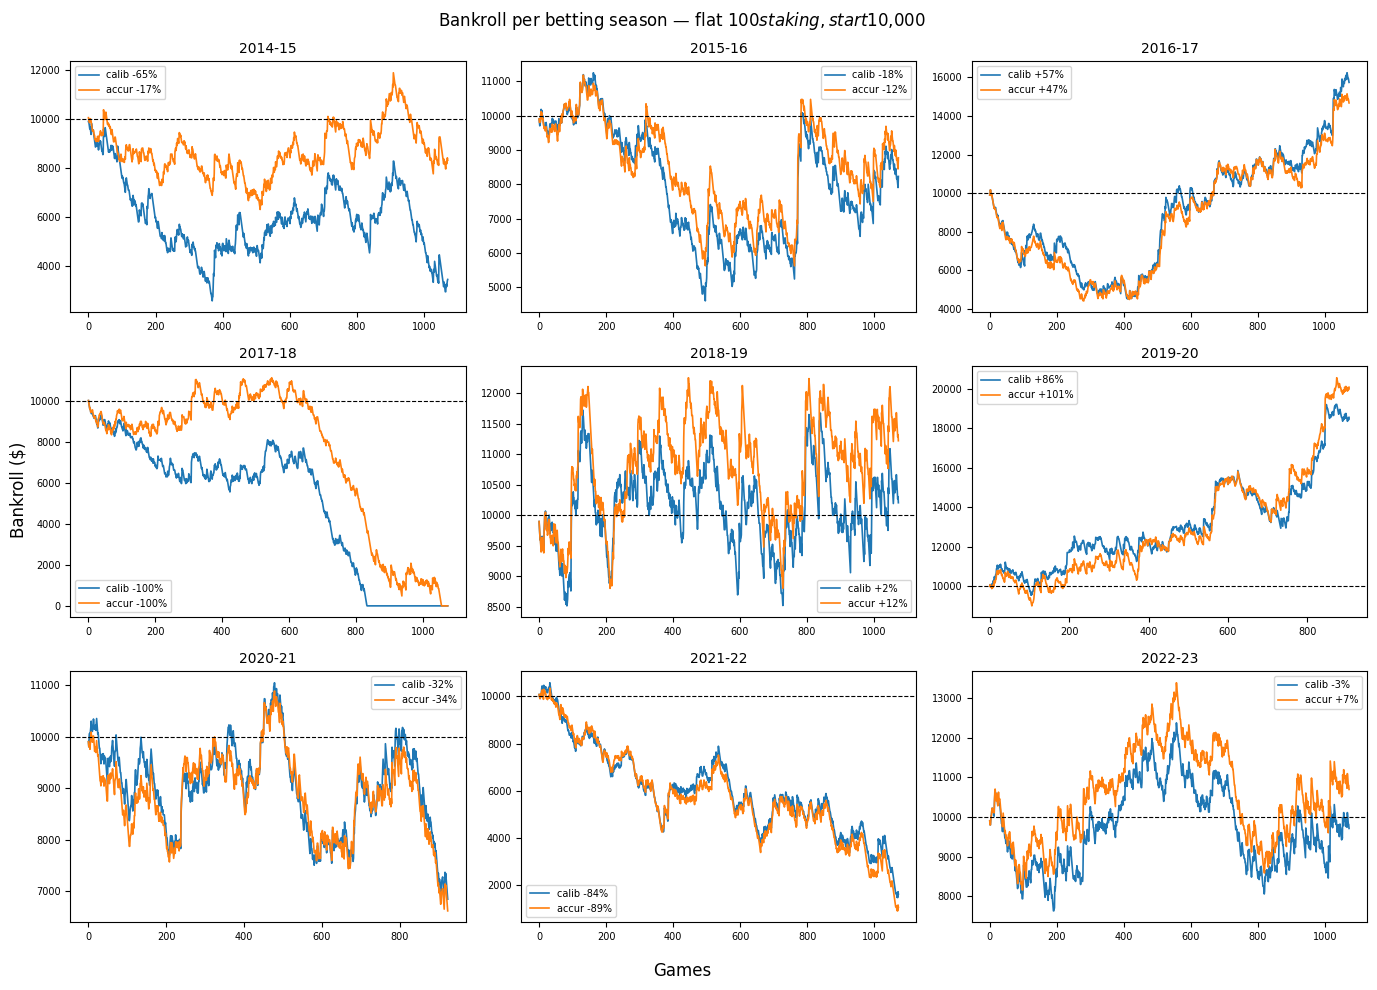

In [70]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, r in zip(axes.ravel(), rows):
    ax.plot(r["curve_cal_fixed"], lw=1.2, label=f"calib {r['cal_fixed']:+.0f}%")
    ax.plot(r["curve_acc_fixed"], lw=1.2, label=f"accur {r['acc_fixed']:+.0f}%")
    ax.axhline(10000, ls="--", c="k", lw=.8)
    ax.set_title(r["season"], fontsize=10)
    ax.legend(fontsize=7); ax.tick_params(labelsize=7)
fig.suptitle("Bankroll per betting season — flat $100 staking, start $10,000")
fig.supxlabel("Games"); fig.supylabel("Bankroll ($)")
plt.tight_layout(); plt.show()

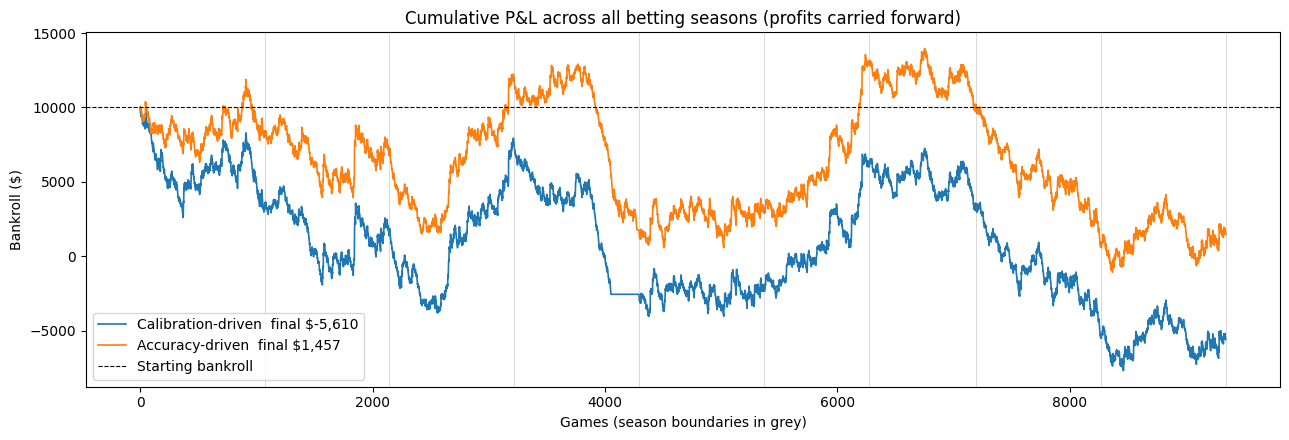

In [71]:
import numpy as np

fig, ax = plt.subplots(figsize=(13, 4.5))
for tag, lbl in [("cal", "Calibration-driven"), ("acc", "Accuracy-driven")]:
    path, base = [], 10000
    for r in rows:
        c = np.array(r[f"curve_{tag}_fixed"])
        path.extend(list(c - 10000 + base))
        base = path[-1]
    ax.plot(path, lw=1.2, label=f"{lbl}  final ${path[-1]:,.0f}")

ax.axhline(10000, ls="--", c="k", lw=.8, label="Starting bankroll")
b = 0
for r in rows:
    b += len(r["curve_cal_fixed"]); ax.axvline(b, color="gray", lw=.4, alpha=.5)
ax.set_title("Cumulative P&L across all betting seasons (profits carried forward)")
ax.set_xlabel("Games (season boundaries in grey)"); ax.set_ylabel("Bankroll ($)")
ax.legend(); plt.tight_layout(); plt.show()